<a href="https://colab.research.google.com/github/2026ct05070/ML_assignment_2/blob/main/ML_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction - ML Assignment 2
**M.Tech (AIML/DSE) - Machine Learning**

**Problem statement:** Predict whether a telecom customer will churn (`Churn` = Yes/No) from account, service and billing information, and compare five classification models: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes and Random Forest.

**Dataset:** Telco Customer Churn (Kaggle, IBM sample data) - 7,043 rows, 20 features + target.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Setup & load data

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef, confusion_matrix)

SEED = 42
TARGET = "Churn"
DATA_FILE = "/content/drive/MyDrive/inputs/WA_Fn-UseC_-Telco-Customer-Churn.csvv"
sns.set_theme(style="whitegrid")

In [10]:
# In Google Colab: run this cell and choose the CSV when asked to upload.
# (If the file already exists in the working folder, the upload is skipped.)
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_FILE = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_FILE} next to this notebook.")

raw = pd.read_csv(DATA_FILE)
print("Shape:", raw.shape)
raw.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Dataset understanding
- **Target variable:** `Churn` (Yes = customer left, No = stayed) - binary classification.
- **Why this dataset:** a realistic business problem with a mix of numeric and categorical features, a hidden missing-value issue (`TotalCharges`) and an imbalanced target.

In [11]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [12]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
binary_cols = ["SeniorCitizen"]
id_cols = ["customerID"]
categorical_cols = [c for c in raw.columns if c not in numeric_cols + binary_cols + id_cols + [TARGET]]

print("Numeric features   :", numeric_cols)
print("Binary (0/1)       :", binary_cols)
print(f"Categorical ({len(categorical_cols)})   :", categorical_cols)
print("Identifier (dropped):", id_cols)

Numeric features   : ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary (0/1)       : ['SeniorCitizen']
Categorical (15)   : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Identifier (dropped): ['customerID']


In [ ]:
counts = raw[TARGET].value_counts()
pct = (counts / len(raw) * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))
print(f"\nImbalance ratio (No:Yes) = {counts['No']/counts['Yes']:.2f} : 1")

ax = sns.countplot(x=TARGET, data=raw, hue=TARGET, palette=["#4C72B0", "#C44E52"], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Class distribution - Churn")
plt.show()

## 2. Data preprocessing
Steps: missing values -> duplicates -> train/test split (80:20, stratified, seed 42) -> encoding + scaling **fitted on training data only** (done inside a `Pipeline`, so there is no leakage).

In [13]:
df = raw.copy()

# `TotalCharges` is read as text because some entries are blank strings -> convert to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
df = df.replace(r"^\s*$", np.nan, regex=True)

miss = df.isna().sum()
print("Missing values per column:")
print(miss[miss > 0] if miss.any() else "none")
print("\nRows with missing TotalCharges (all have tenure == 0):")
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())

Missing values per column:
TotalCharges    11
dtype: int64

Rows with missing TotalCharges (all have tenure == 0):
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No


In [14]:
# Duplicates (ignoring the unique customerID)
df = df.drop(columns=id_cols)
n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

y = (df[TARGET] == "Yes").astype(int)
X = df.drop(columns=[TARGET])

Duplicate rows: 22
Shape after removing duplicates: (7021, 20)


In [15]:
# 80:20 split, stratified so the churn ratio is the same in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

# keep the test set as a CSV (required for the GitHub repo)
test_out = X_test.copy()
test_out[TARGET] = np.where(y_test == 1, "Yes", "No")
test_out.to_csv("test_data.csv", index=False)

Train: (5616, 19) | Test: (1405, 19)
Churn rate  train: 0.264  test: 0.265


In [16]:
# Missing values: median (numeric) / most-frequent (categorical); scaling for numeric; one-hot for categorical.
# Everything is fitted on X_train only, because it lives inside the Pipeline.
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_cols),
        ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         categorical_cols),
    ])

## 3. Models and evaluation
Five models on the same train/test split. Positive class = `Churn = Yes`. AUC uses predicted probabilities.

In [17]:
models = {
    "Logistic Regression":    LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree":          DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=SEED),
    "KNN":                    KNeighborsClassifier(n_neighbors=11),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Random Forest":          RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                                     n_jobs=-1, random_state=SEED),
}

rows, conf_mats = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "AUC":       roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "MCC":       matthews_corrcoef(y_test, pred),
    })
    conf_mats[name] = confusion_matrix(y_test, pred)

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8028,0.8403,0.6610,0.5242,0.5847,0.4630
Decision Tree,0.8000,0.8308,0.6435,0.5484,0.5922,0.4634
KNN,0.7744,0.8089,0.5857,0.5054,0.5426,0.3958
Naive Bayes (Gaussian),0.6861,0.8092,0.4501,0.8360,0.5851,0.4132
Random Forest,0.7986,0.8395,0.6606,0.4919,0.5639,0.4446


In [18]:
results.to_csv("metrics_comparison.csv")
print(results.reset_index().to_markdown(index=False))   # paste this table into the README

| Model                  |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.8028 | 0.8403 |      0.661  |   0.5242 | 0.5847 | 0.463  |
| Decision Tree          |     0.8    | 0.8308 |      0.6435 |   0.5484 | 0.5922 | 0.4634 |
| KNN                    |     0.7744 | 0.8089 |      0.5857 |   0.5054 | 0.5426 | 0.3958 |
| Naive Bayes (Gaussian) |     0.6861 | 0.8092 |      0.4501 |   0.836  | 0.5851 | 0.4132 |
| Random Forest          |     0.7986 | 0.8395 |      0.6606 |   0.4919 | 0.5639 | 0.4446 |


## 4. Visualisation of metrics

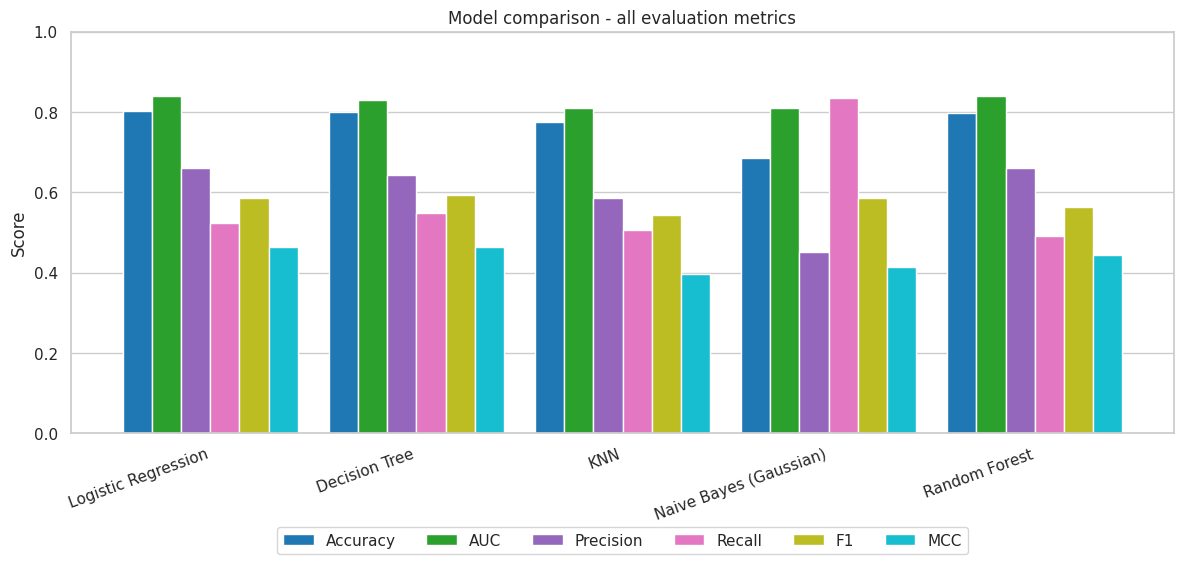

In [19]:
ax = results.plot(kind="bar", figsize=(12, 6), width=0.85, colormap="tab10")
ax.set_title("Model comparison - all evaluation metrics")
ax.set_ylabel("Score"); ax.set_xlabel("")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 1.0)
ax.legend(loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.32))
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("metrics_bar_chart.png", dpi=150)
plt.show()

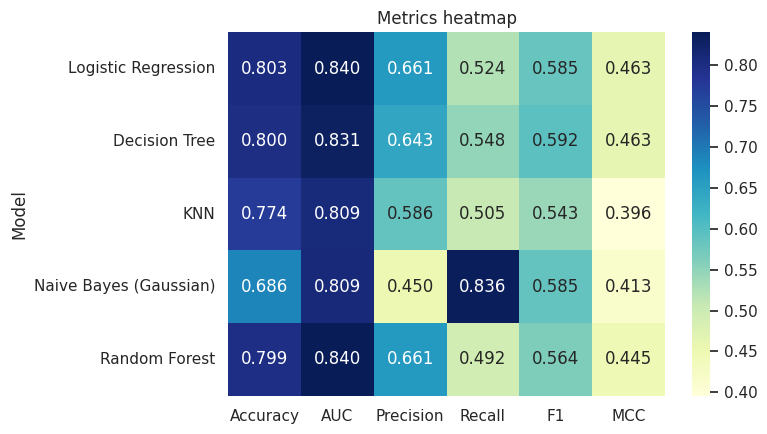

In [20]:
plt.figure(figsize=(8, 4.5))
sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Metrics heatmap")
plt.tight_layout()
plt.savefig("metrics_heatmap.png", dpi=150)
plt.show()

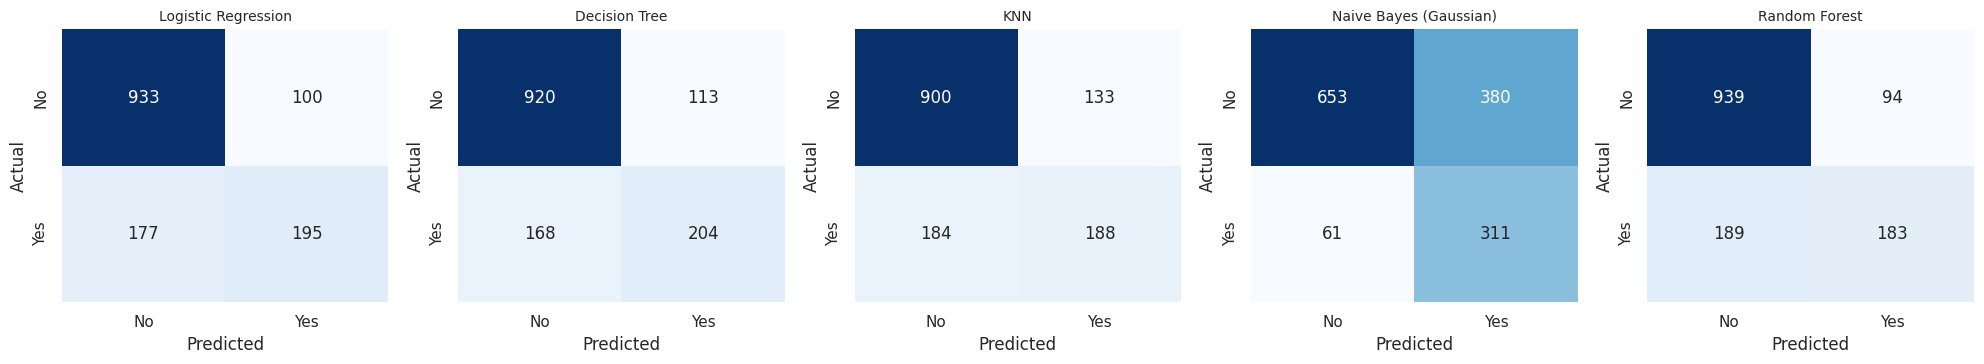

In [21]:
fig, axes = plt.subplots(1, len(conf_mats), figsize=(4*len(conf_mats), 3.8))
for ax, (name, cm) in zip(axes, conf_mats.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(name, fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

## 5. Observations

**Observations** (test set: 1,405 customers, 26.5% churners; positive class = Churn)

| Model | Observation |
|---|---|
| Logistic Regression | Best overall balance: highest accuracy (0.803) and AUC (0.840) with the best precision (0.661, tied with Random Forest). It catches 195 of 372 churners (recall 0.524). Churn here is driven mostly by tenure, contract type and monthly charges, which a linear model captures well, and it is fast and interpretable. |
| Decision Tree | Accuracy (0.800) and AUC (0.831) are very close to Logistic Regression, and it has the best F1 (0.592) and MCC (0.463). Limiting depth (6) and leaf size (20) kept it from overfitting. Its lower AUC means its probability ranking is a bit coarser, since a tree outputs only a few distinct probabilities. |
| KNN | Weakest of the balanced models: lowest accuracy (0.774), AUC (0.809) and MCC (0.396). After one-hot encoding there are about 40 mostly binary dimensions, so distances are less meaningful, and the majority class dominates neighbourhoods. |
| Naive Bayes (Gaussian) | Behaves very differently: highest recall (0.836, 311 of 372 churners found) but lowest precision (0.450) and accuracy (0.686), with 380 false alarms. Its AUC (0.809) is not far behind the others, so its ranking is fine but its probabilities are poorly calibrated. Gaussian assumptions on one-hot features and strongly correlated features (e.g. TotalCharges vs tenure) push it to over-predict churn. It would suit a campaign where missing a churner costs far more than a wasted offer. |
| Random Forest | Second-best AUC (0.840, almost equal to Logistic Regression) and the highest TN count, but recall is the lowest (0.492) and F1 is only 0.564. On imbalanced data it favours the majority class at the default 0.5 threshold. A lower decision threshold or `class_weight="balanced"` would likely raise recall. |

**Overall:** Logistic Regression is the best all-round model (accuracy, AUC, precision), with Random Forest and Decision Tree close behind. The ensemble did not clearly beat the simple linear model, which suggests the signal in this dataset is mostly linear and simple. Because only 26.5% of customers churn, accuracy alone is misleading (always predicting "No" would score about 73.5%), so AUC, F1 and MCC are the better yardsticks. Which model is "best" depends on the business cost: if retaining a churner is worth more than a wasted offer, Naive Bayes's high recall is attractive; if offers are expensive, Logistic Regression or Random Forest, with higher precision, fit better.

In [22]:
# Colab only: download the generated files (test set, table, charts) to add to your GitHub repo
try:
    from google.colab import files
    for f in ["test_data.csv", "metrics_comparison.csv", "metrics_bar_chart.png",
              "metrics_heatmap.png", "confusion_matrices.png"]:
        files.download(f)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>